<a href="https://colab.research.google.com/github/pallavisolse86-sys/AI-Based-Air-Quality-Monitoring-Dashboard/blob/main/MiniProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io

from google.colab import files
from IPython.display import display

# Upload your CSV file
uploaded = files.upload()

# Read the uploaded CSV file
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Uploaded file:", filename)
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Saving air_quality_data.csv to air_quality_data.csv
Uploaded file: air_quality_data.csv
Dataset shape: (29531, 16)

First 5 rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Column names:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 n

In [2]:

# Make column names consistent
df.columns = df.columns.str.strip()

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert Date column if present
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert common air quality columns to numeric
numeric_cols = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene",
    "Toluene", "Xylene", "AQI"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Dataset shape after removing duplicates:", df.shape)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nStatistical summary:")
display(df.describe(include="all").T)


Dataset shape after removing duplicates: (29531, 16)

Missing values:


,0
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022



Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
City,29531,26,Ahmedabad,2009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,29531,NaN,NaN,NaN,2018-05-14 05:40:15.807118080,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,NaN,NaN,NaN,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,NaN,NaN,NaN,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,NaN,NaN,NaN,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,NaN,NaN,NaN,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,NaN,NaN,NaN,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,NaN,NaN,NaN,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,NaN,NaN,NaN,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,NaN,NaN,NaN,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775


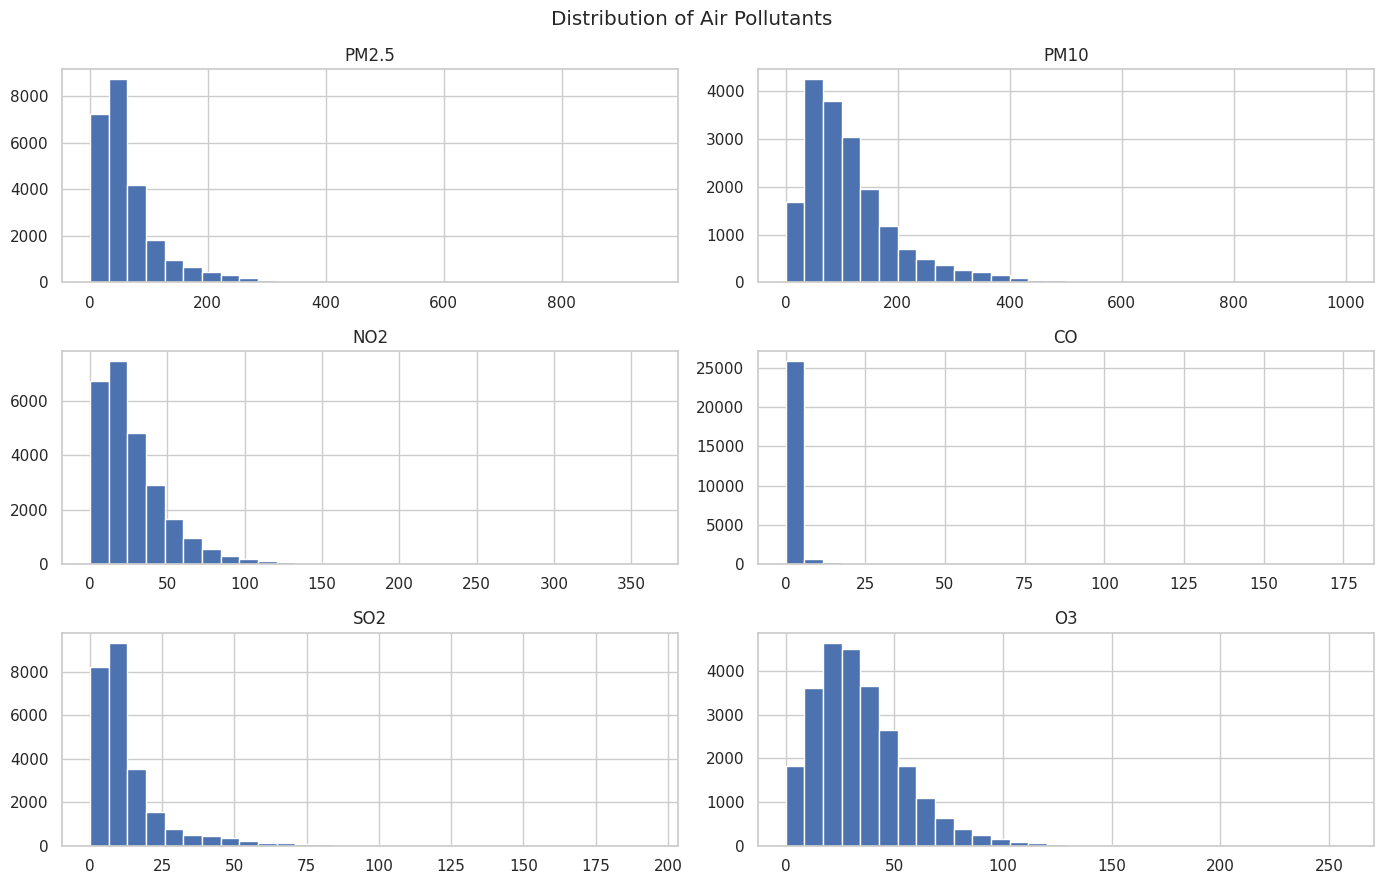

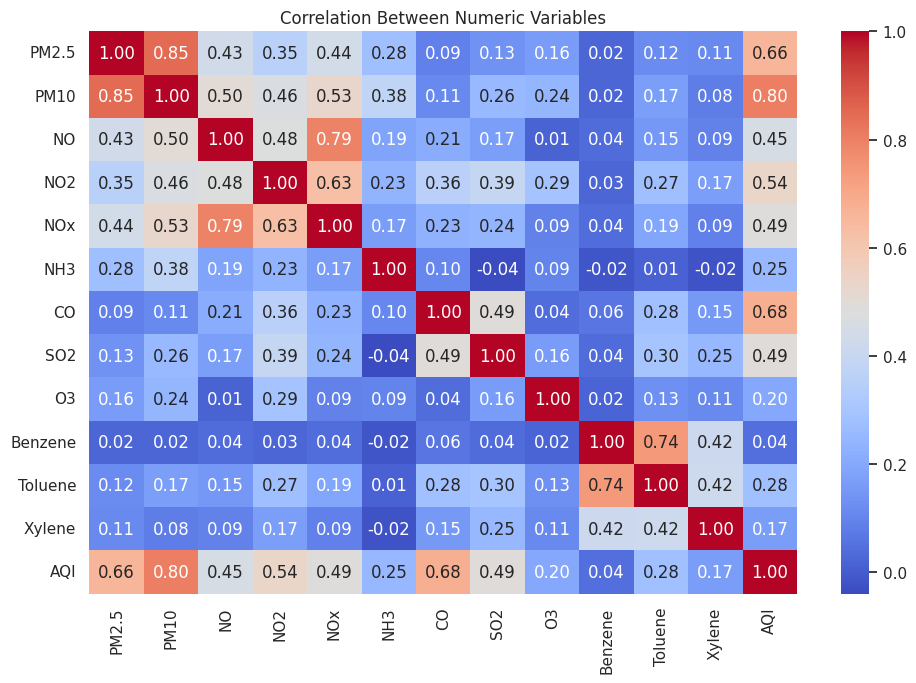

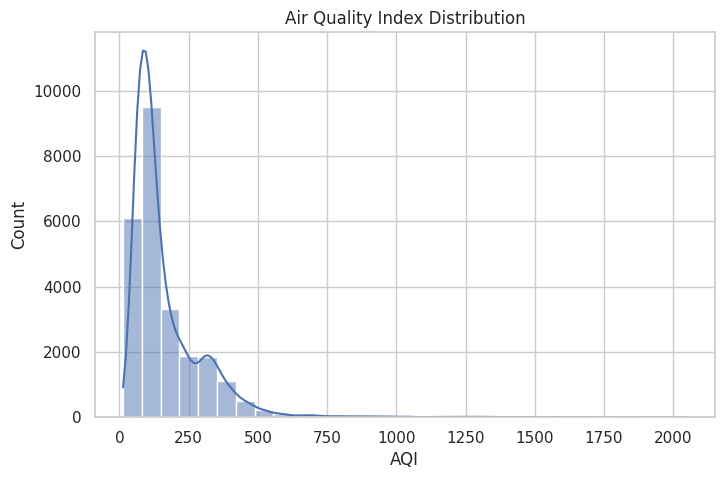

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot pollutant distributions
pollutants = [
    col for col in ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]
    if col in df.columns
]

if pollutants:
    df[pollutants].hist(figsize=(14, 9), bins=30)
    plt.suptitle("Distribution of Air Pollutants")
    plt.tight_layout()
    plt.show()
else:
    print("No standard pollutant columns found.")

# Correlation heatmap
numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        numeric_df.corr(),
        cmap="coolwarm",
        annot=True,
        fmt=".2f"
    )
    plt.title("Correlation Between Numeric Variables")
    plt.tight_layout()
    plt.show()

# AQI distribution
if "AQI" in df.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(df["AQI"].dropna(), bins=30, kde=True)
    plt.title("Air Quality Index Distribution")
    plt.xlabel("AQI")
    plt.show()


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Check that the target column exists
if "AQI" not in df.columns:
    raise ValueError(
        "AQI column not found. Check your CSV column names."
    )

# Select available pollutant features
possible_features = [
    "PM2.5", "PM10", "NO", "NO2", "NOx",
    "NH3", "CO", "SO2", "O3", "Benzene",
    "Toluene", "Xylene"
]

features = [c for c in possible_features if c in df.columns]

# Include city when available
if "City" in df.columns:
    features.append("City")

if not features:
    raise ValueError("No suitable pollutant features found.")

# Remove rows without a known target value
data = df.dropna(subset=["AQI"]).copy()

X = data[features]
y = data["AQI"]

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = [
    c for c in X.columns if c not in categorical_features
]

# Build preprocessing pipelines
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Model evaluation results")
print("-------------------------")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))
print("R² score:", round(r2_score(y_test, y_pred), 3))


Model evaluation results
-------------------------
MAE: 20.434
RMSE: 40.374
R² score: 0.911


,Actual_AQI,Predicted_AQI
0,141.0,93.68
1,209.0,207.22
2,111.0,102.15
3,124.0,144.89
4,81.0,76.85
5,54.0,63.55
6,74.0,65.52
7,99.0,103.16
8,97.0,133.81
9,60.0,61.06


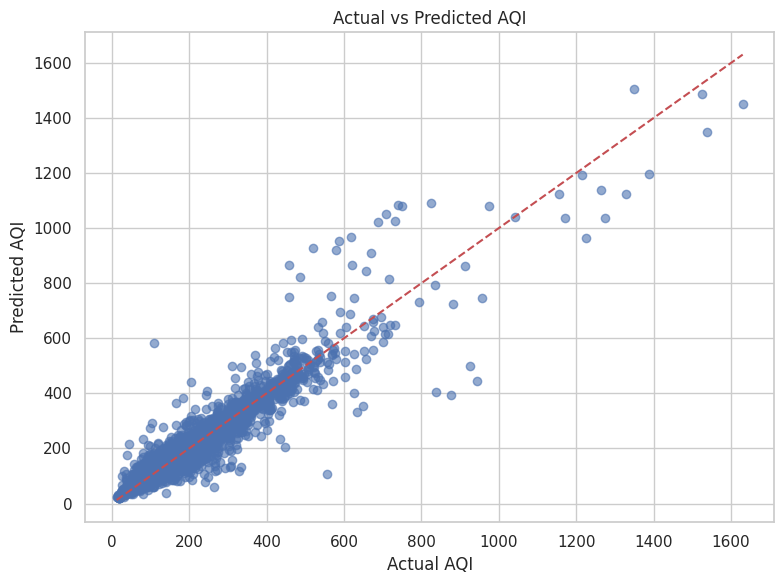

Prediction results saved successfully.


In [6]:

results = pd.DataFrame({
    "Actual_AQI": y_test.to_numpy(),
    "Predicted_AQI": y_pred
})

display(results.head(10))

plt.figure(figsize=(8, 6))
plt.scatter(
    results["Actual_AQI"],
    results["Predicted_AQI"],
    alpha=0.6
)

low = min(results["Actual_AQI"].min(),
          results["Predicted_AQI"].min())
high = max(results["Actual_AQI"].max(),
           results["Predicted_AQI"].max())

plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI")
plt.tight_layout()
plt.show()

results.to_csv("aqi_predictions.csv", index=False)
print("Prediction results saved successfully.")


,Model,MAE,RMSE,R2 Score
2,Random Forest,20.434,40.374,0.911
0,Linear Regression,30.060,56.797,0.824
1,Decision Tree,28.497,57.971,0.816


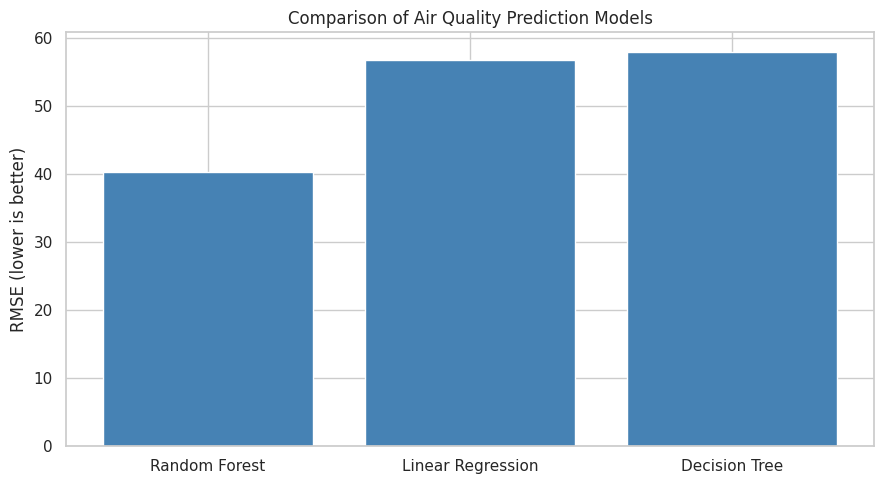

In [7]:

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

comparison = []

for name, regressor in models.items():
    # Reuse the preprocessing fitted within your existing pipeline
    experiment = clone(model)
    experiment.set_params(regressor=regressor)

    experiment.fit(X_train, y_train)
    predictions = experiment.predict(X_test)

    comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison).sort_values("RMSE")

display(comparison_df.round(3))

comparison_df.to_csv("model_comparison.csv", index=False)

plt.figure(figsize=(9, 5))
plt.bar(comparison_df["Model"], comparison_df["RMSE"], color="steelblue")
plt.ylabel("RMSE (lower is better)")
plt.title("Comparison of Air Quality Prediction Models")
plt.tight_layout()
plt.show()


In [8]:

# Save model comparison results
comparison_df.to_csv("model_comparison.csv", index=False)

# Display results sorted by RMSE
display(comparison_df.sort_values("RMSE").round(3))

# Download the CSV file
from google.colab import files
files.download("model_comparison.csv")


,Model,MAE,RMSE,R2 Score
2,Random Forest,20.434,40.374,0.911
0,Linear Regression,30.060,56.797,0.824
1,Decision Tree,28.497,57.971,0.816


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

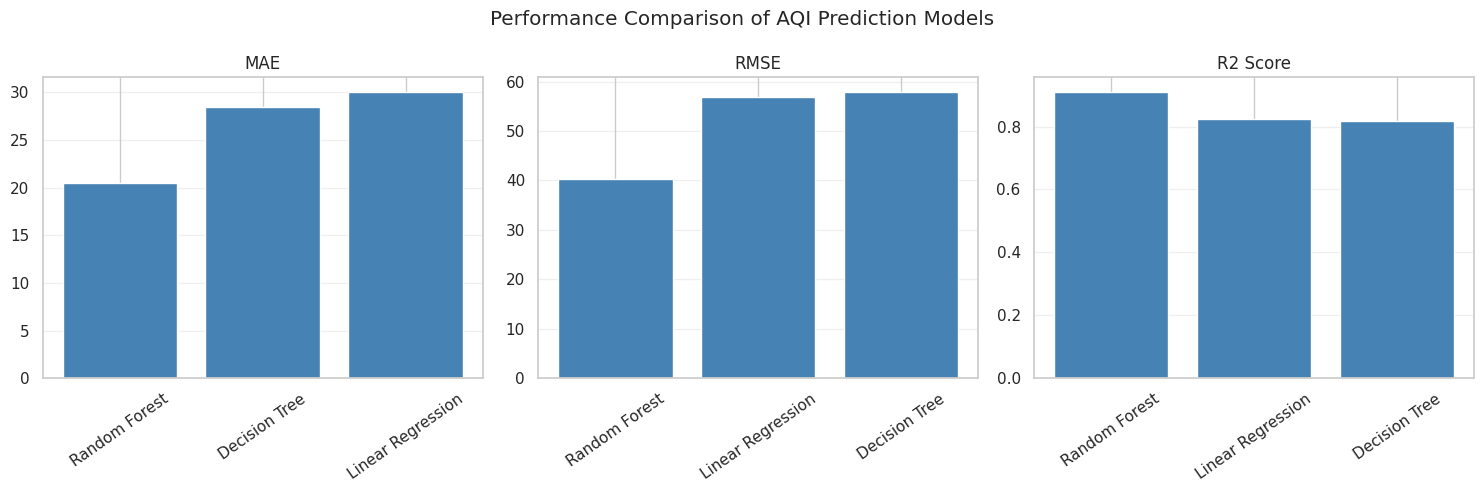

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

import matplotlib.pyplot as plt

metrics = ["MAE", "RMSE", "R2 Score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, metrics):
    ordered = comparison_df.sort_values(
        metric,
        ascending=(metric != "R2 Score")
    )

    ax.bar(ordered["Model"], ordered[metric], color="steelblue")
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Performance Comparison of AQI Prediction Models")
plt.tight_layout()
plt.savefig("model_comparison_graph.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("model_comparison_graph.png")


Feature Importance Results:


,Feature,Importance,Std
0,PM2.5,51.5787,0.3817
6,CO,24.4422,0.6701
1,PM10,17.0710,0.3474
8,O3,3.3747,0.0972
12,City,2.5611,0.1575
2,NO,2.0642,0.1494
4,NOx,1.4894,0.0486
3,NO2,0.6452,0.0384
10,Toluene,0.4133,0.0381
11,Xylene,0.3620,0.0449


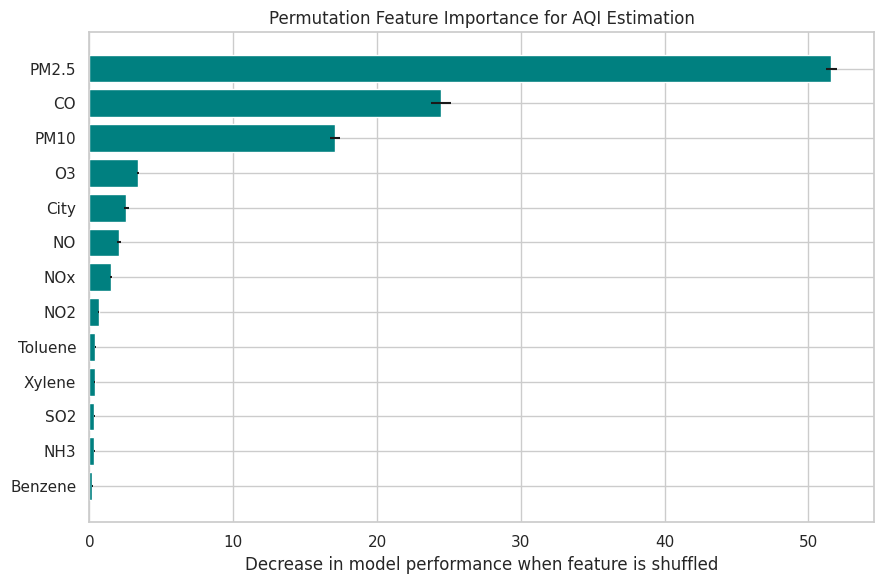

Saved feature_importance.csv and feature_importance.png


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# Use the trained Random Forest pipeline: model
# Calculate permutation importance on the test dataset
importance_result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
}).sort_values("Importance", ascending=False)

print("Feature Importance Results:")
display(importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1],
    xerr=importance_df["Std"][::-1],
    color="teal"
)
plt.xlabel("Decrease in model performance when feature is shuffled")
plt.title("Permutation Feature Importance for AQI Estimation")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

# Save results
importance_df.to_csv("feature_importance.csv", index=False)
print("Saved feature_importance.csv and feature_importance.png")


In [15]:

import os
import joblib
import pandas as pd

PROJECT_DIR = "/content/air_quality_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

# Save the dataset already loaded in your notebook
df.to_csv(f"{PROJECT_DIR}/air_quality_data.csv", index=False)

# Save your trained Random Forest pipeline
joblib.dump(model, f"{PROJECT_DIR}/air_quality_model.pkl")

# Save comparison results if available
if "comparison_df" in globals():
    comparison_df.to_csv(
        f"{PROJECT_DIR}/model_comparison.csv", index=False
    )

# Save feature importance results if available
if "importance_df" in globals():
    importance_df.to_csv(
        f"{PROJECT_DIR}/feature_importance.csv", index=False
    )

print("Project files saved successfully!")
print(os.listdir(PROJECT_DIR))


Project files saved successfully!
['feature_importance.csv', 'air_quality_model.pkl', 'model_comparison.csv', 'air_quality_data.csv', 'app.py']


In [16]:

%pip -q install streamlit plotly joblib


In [17]:

%%writefile /content/air_quality_project/app.py

import os
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px

BASE = "/content/air_quality_project"
DATA_PATH = f"{BASE}/air_quality_data.csv"
MODEL_PATH = f"{BASE}/air_quality_model.pkl"
COMPARISON_PATH = f"{BASE}/model_comparison.csv"
IMPORTANCE_PATH = f"{BASE}/feature_importance.csv"

st.set_page_config(
    page_title="Air Quality Intelligence",
    page_icon="🌍",
    layout="wide"
)

st.title("🌍 AI-Based Air Quality Monitoring Dashboard")
st.caption(
    "Research project | Air pollution analysis and machine-learning AQI estimation"
)

@st.cache_data
def load_data():
    data = pd.read_csv(DATA_PATH)
    if "Date" in data.columns:
        data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    return data

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

df = load_data()
model = load_model()

# Sidebar navigation
st.sidebar.title("Navigation")
page = st.sidebar.radio(
    "Choose a section",
    [
        "Dashboard Overview",
        "Explore Air Quality",
        "AQI Prediction",
        "Model Evaluation",
        "Feature Importance"
    ]
)

if page == "Dashboard Overview":
    st.header("Air Quality Overview")

    c1, c2, c3 = st.columns(3)

    c1.metric("Total records", f"{len(df):,}")
    c2.metric(
        "Cities",
        str(df["City"].nunique()) if "City" in df.columns else "N/A"
    )

    if "AQI" in df.columns:
        c3.metric(
            "Average AQI",
            f"{df['AQI'].mean():.1f}" if df["AQI"].notna().any() else "N/A"
        )
    else:
        c3.metric("AQI available", "No")

    st.subheader("Dataset preview")
    st.dataframe(df.head(20), use_container_width=True)

    if "AQI" in df.columns:
        chart_df = df.dropna(subset=["AQI"])

        st.subheader("AQI distribution")
        fig = px.histogram(
            chart_df,
            x="AQI",
            nbins=40,
            title="Distribution of recorded AQI values"
        )
        st.plotly_chart(fig, use_container_width=True)

    pollutants = [
        c for c in ["PM2.5", "PM10", "CO", "NO2", "SO2", "O3"]
        if c in df.columns
    ]

    if pollutants:
        st.subheader("Pollutant distributions")
        selected_pollutant = st.selectbox(
            "Select pollutant", pollutants
        )
        fig = px.histogram(
            df,
            x=selected_pollutant,
            nbins=40,
            title=f"{selected_pollutant} distribution"
        )
        st.plotly_chart(fig, use_container_width=True)

elif page == "Explore Air Quality":
    st.header("Explore Air Quality Data")

    filtered = df.copy()

    if "City" in filtered.columns:
        cities = sorted(
            filtered["City"].dropna().astype(str).unique().tolist()
        )
        selected_cities = st.multiselect(
            "Select cities",
            cities,
            default=cities[:min(5, len(cities))]
        )
        filtered = filtered[
            filtered["City"].astype(str).isin(selected_cities)
        ]

    if "Date" in filtered.columns and filtered["Date"].notna().any():
        valid_dates = filtered["Date"].dropna()
        start_date = st.date_input(
            "Start date", value=valid_dates.min().date()
        )
        end_date = st.date_input(
            "End date", value=valid_dates.max().date()
        )

        if start_date <= end_date:
            filtered = filtered[
                filtered["Date"].isna()
                | (
                    (filtered["Date"].dt.date >= start_date)
                    & (filtered["Date"].dt.date <= end_date)
                )
            ]
        else:
            st.warning("Start date must be before end date.")

    st.write(f"Records matching filters: {len(filtered):,}")
    st.dataframe(filtered, use_container_width=True)

    numeric_cols = filtered.select_dtypes(include="number").columns.tolist()

    if len(numeric_cols) >= 1 and not filtered.empty:
        variable = st.selectbox(
            "Choose a variable to visualize", numeric_cols
        )
        fig = px.line(
            filtered.sort_values("Date") if "Date" in filtered.columns else filtered,
            x="Date" if "Date" in filtered.columns else filtered.index,
            y=variable,
            color="City" if "City" in filtered.columns else None,
            title=f"{variable} across records"
        )
        st.plotly_chart(fig, use_container_width=True)

    st.download_button(
        "Download filtered CSV",
        data=filtered.to_csv(index=False).encode("utf-8"),
        file_name="filtered_air_quality.csv",
        mime="text/csv"
    )

elif page == "AQI Prediction":
    st.header("Estimate AQI with Machine Learning")
    st.info(
        "Enter pollutant measurements to estimate AQI. "
        "This model estimates AQI; it does not forecast future AQI."
    )

    if not hasattr(model, "feature_names_in_"):
        st.error(
            "The model does not expose its training feature names. "
            "Check that the saved model is the fitted pipeline."
        )
        st.stop()

    features = list(model.feature_names_in_)
    inputs = {}

    with st.form("prediction_form"):
        st.subheader("Input measurements")

        columns = st.columns(2)

        for i, feature in enumerate(features):
            with columns[i % 2]:
                if feature not in df.columns:
                    st.error(
                        f"Required model feature '{feature}' "
                        "is not present in the dataset."
                    )
                    continue

                if (
                    feature == "City"
                    or not pd.api.types.is_numeric_dtype(df[feature])
                ):
                    options = sorted(
                        df[feature].dropna().astype(str).unique().tolist()
                    )
                    if not options:
                        options = ["Unknown"]
                    inputs[feature] = st.selectbox(feature, options)
                else:
                    values = pd.to_numeric(
                        df[feature], errors="coerce"
                    ).dropna()

                    default = float(values.median()) if len(values) else 0.0
                    minimum = float(values.min()) if len(values) else 0.0
                    maximum = float(values.max()) if len(values) else max(default, 1.0)

                    inputs[feature] = st.number_input(
                        feature,
                        min_value=minimum if minimum <= default else default,
                        max_value=maximum if maximum >= default else default,
                        value=default
                    )

        submitted = st.form_submit_button("Estimate AQI")

    if submitted:
        input_df = pd.DataFrame([inputs], columns=features)

        try:
            prediction = float(model.predict(input_df)[0])
            st.success(f"Estimated AQI: {prediction:.2f}")
            st.caption(
                "This is a model estimate. Interpret it using the applicable "
                "AQI standard; it is not a live sensor reading."
            )

            result = input_df.copy()
            result["Predicted_AQI"] = prediction

            st.dataframe(result, use_container_width=True)
            st.download_button(
                "Download prediction",
                data=result.to_csv(index=False).encode("utf-8"),
                file_name="aqi_prediction.csv",
                mime="text/csv"
            )
        except Exception as e:
            st.error(f"Prediction failed: {e}")

elif page == "Model Evaluation":
    st.header("Model Comparison and Evaluation")

    if os.path.exists(COMPARISON_PATH):
        comparison = pd.read_csv(COMPARISON_PATH)
        st.dataframe(comparison.round(4), use_container_width=True)

        metric_options = [
            c for c in ["MAE", "RMSE", "R2 Score"]
            if c in comparison.columns
        ]

        if metric_options and "Model" in comparison.columns:
            metric = st.selectbox("Select evaluation metric", metric_options)
            fig = px.bar(
                comparison,
                x="Model",
                y=metric,
                title=f"Model comparison: {metric}"
            )
            st.plotly_chart(fig, use_container_width=True)

        st.download_button(
            "Download comparison CSV",
            data=comparison.to_csv(index=False).encode("utf-8"),
            file_name="model_comparison.csv",
            mime="text/csv"
        )
    else:
        st.warning(
            "Comparison file not found. Save comparison_df from your notebook "
            "to model_comparison.csv in the project folder."
        )

elif page == "Feature Importance":
    st.header("Feature Importance Analysis")

    if os.path.exists(IMPORTANCE_PATH):
        importance = pd.read_csv(IMPORTANCE_PATH)
        st.dataframe(importance.round(4), use_container_width=True)

        if {"Feature", "Importance"}.issubset(importance.columns):
            importance = importance.sort_values("Importance")
            fig = px.bar(
                importance,
                x="Importance",
                y="Feature",
                orientation="h",
                error_x="Std" if "Std" in importance.columns else None,
                title="Permutation Feature Importance"
            )
            st.plotly_chart(fig, use_container_width=True)

        st.download_button(
            "Download feature importance CSV",
            data=importance.to_csv(index=False).encode("utf-8"),
            file_name="feature_importance.csv",
            mime="text/csv"
        )
    else:
        st.warning("Feature importance CSV was not found.")

st.divider()
st.caption(
    "Academic prototype based on historical dataset records. "
    "Predictions depend on the training data and model quality."
)


Overwriting /content/air_quality_project/app.py


In [20]:
import os

log_path = "/content/streamlit_fresh.log"

if os.path.exists(log_path):
    with open(log_path, "r") as f:
        logs = f.read()
    print(logs[-8000:])
else:
    print(f"Log file not found at {log_path}. Please execute the Streamlit startup cell first.")

Log file not found at /content/streamlit_fresh.log. Please execute the Streamlit startup cell first.


In [21]:

import os
import sys
import time
import subprocess
import requests
from google.colab import output
from IPython.display import display, HTML

APP = "/content/air_quality_project/app.py"
LOG = "/content/streamlit_fresh.log"
PORT = 8501

# Stop tracked previous process
if "process" in globals() and process.poll() is None:
    process.terminate()
    try:
        process.wait(timeout=5)
    except subprocess.TimeoutExpired:
        process.kill()

# Ensure app exists
if not os.path.isfile(APP):
    raise FileNotFoundError(f"Missing app: {APP}")

# Write explicit Streamlit configuration
config_dir = os.path.expanduser("~/.streamlit")
os.makedirs(config_dir, exist_ok=True)

config_path = os.path.join(config_dir, "config.toml")
with open(config_path, "w") as f:
    f.write("""
[server]
headless = true
address = "0.0.0.0"
port = 8501
enableCORS = false
enableXsrfProtection = false
enableWebsocketCompression = false

[browser]
gatherUsageStats = false
""")

# Start a fresh server with a new log
log_handle = open(LOG, "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", APP,
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--server.enableWebsocketCompression=false",
        "--server.headless=true"
    ],
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

# Wait for the local server
healthy = False

for _ in range(30):
    if process.poll() is not None:
        break
    try:
        r = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )
        if r.status_code == 200:
            healthy = True
            break
    except requests.RequestException:
        pass
    time.sleep(2)

log_handle.flush()

if healthy:
    print("Local Streamlit server is healthy.")
    url = output.eval_js(
        "google.colab.kernel.proxyPort(8501)"
    )
    display(HTML(
        f'<a href="{url}" target="_blank">'
        '<h3>Open Air Quality Dashboard</h3></a>'
    ))
else:
    print("Server failed to start.")
    with open(LOG, "r") as f:
        print(f.read()[-8000:])

log_handle.close()


Local Streamlit server is healthy.
